In [ ]:
##########################################  Actividad 4 - Análisis de Sentimientos de reseñas   #########################################


####################  Instalación de dependencias, importar librerías, reproducibilidad y autenticación Hugging Face  ###################

# Instalación de dependencias
!pip install -q transformers torch accelerate huggingface_hub kagglehub pandas scikit-learn matplotlib seaborn


# Importar librerías
import torch
import numpy as np
import pandas as pd
import os, random, time, gc, platform
import transformers, kagglehub, sklearn

from pathlib import Path
from huggingface_hub import login
from IPython.display import display


# Definición de semilla para garantizar reproducibilidad
SEED=42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)


# Activar GPU en Colab -> Entorno de ejecución -> Cambiar tipo > GPU
DEVICE=0

assert torch.cuda.is_available()
print("GPU:", torch.cuda.get_device_name(0))


# Autenticación en Hugging Face
try:
    from google.colab import userdata
    token=userdata.get("HF_TOKEN")
except (ImportError, KeyError, Exception) as exc:
    token=os.environ.get("HF_TOKEN")
    print("Se utilizará token de entorno o acceso público.")
if token:
    login(token=token, add_to_git_credential=False)
    print("Hugging Face: autenticación realizada")
else:
    print("Hugging Face: sin token; modelos públicos accesibles sin login")



GPU: Tesla T4
Se utilizará token de entorno o acceso público.
Hugging Face: sin token; modelos públicos accesibles sin login


In [ ]:
############################################  Carga de dataset de Kaggle y limpieza de datos  ###########################################

# Descarga directa del dataset de reseñas en Kaggle
path = Path(kagglehub.dataset_download("luisdiegofv97/imdb-dataset-of-50k-movie-reviews-spanish"))
print("Dataset descargado:", path)


# Busca archivos CSV
csv_files = sorted(path.rglob("*.csv"), key=lambda p:p.stat().st_size, reverse=True)
print("Archivos CSV:",[(p.name,p.stat().st_size) for p in csv_files])
if not csv_files:
  raise FileNotFoundError("No se encontraron archivos CSV en la descarga de Kaggle")


# Carga dataset
df_kaggle = pd.read_csv(csv_files[0], low_memory=False)
df_kaggle.columns = df_kaggle.columns.astype(str).str.strip()
print("Dimensiones:", df_kaggle.shape, "Columnas:", df_kaggle.columns.tolist())
display(df_kaggle.head())


# Verifica columnas de reseña y sentimiento
text_col = next((c for c in ["review_es","review_spanish","review"] if c in df_kaggle.columns), None)
label_col = next((c for c in ["sentiment","sentimiento"] if c in df_kaggle.columns), None)

if not text_col or not label_col:
  raise ValueError("Revisar columnas del CSV; no se encontraron reseña y sentimiento esperados")

if text_col == "review":
  raise ValueError("Solo se detectó 'review'; comprobar que el texto esté en español")

print("Columnas seleccionadas:",text_col, label_col)
print("Etiquetas originales:",df_kaggle[label_col].value_counts(dropna=False).head(15).to_dict())


# Mapeo de etiquetas
labels={"positive":"POS", "negative":"NEG", "positivo":"POS", "negativo":"NEG", "pos":"POS", "neg":"NEG"}


# Construye dataframe
df = pd.DataFrame({"text":df_kaggle[text_col], "raw_sentiment":df_kaggle[label_col]})
df["label"] = df["raw_sentiment"].astype(str).str.strip().str.lower().map(labels)


# Limpieza de datos
df = df.dropna(subset=["text","label"]).copy()
df["text"] = df["text"].astype(str).str.replace(r"<br\s*/?>", " ", regex=True, case=False).str.strip()
df = df[df["text"].str.len()>0].drop_duplicates(subset = ["text"]).reset_index(drop=True)
print("Registros válidos:", len(df))
print(df.label.value_counts())

# Valida muestra para validar la proporción y evitar sesgos
assert df.label.nunique() == 2, "Se requieren exactamente las dos clases: POS y NEG"
from sklearn.model_selection import train_test_split
assert len(df)>=300, "No hay 300 registros válidos"

df_eval,_=train_test_split(df,train_size=300, stratify=df.label, random_state=SEED)
df_eval=df_eval.reset_index(drop=True)
print("Muestra:",df_eval.label.value_counts().to_dict())
display(df_eval[["text","label"]].head())

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews-spanish' dataset.
Dataset descargado: /kaggle/input/imdb-dataset-of-50k-movie-reviews-spanish
Archivos CSV: [('IMDB Dataset SPANISH.csv', 137279948)]
Dimensiones: (50000, 5) Columnas: ['Unnamed: 0', 'review_en', 'review_es', 'sentiment', 'sentimiento']


,Unnamed: 0,review_en,review_es,sentiment,sentimiento
0,0,One of the other reviewers has mentioned that ...,Uno de los otros críticos ha mencionado que de...,positive,positivo
1,1,A wonderful little production. The filming tec...,Una pequeña pequeña producción.La técnica de f...,positive,positivo
2,2,I thought this was a wonderful way to spend ti...,Pensé que esta era una manera maravillosa de p...,positive,positivo
3,3,Basically there's a family where a little boy ...,"Básicamente, hay una familia donde un niño peq...",negative,negativo
4,4,"Petter Mattei's ""Love in the Time of Money"" is...","El ""amor en el tiempo"" de Petter Mattei es una...",positive,positivo


Columnas seleccionadas: review_es sentiment
Etiquetas originales: {'positive': 25000, 'negative': 25000}
Registros válidos: 49599
label
POS    24886
NEG    24713
Name: count, dtype: int64
Muestra: {'POS': 151, 'NEG': 149}


,text,label
0,Después de un verano lleno de recauchutados y ...,POS
1,Esta es una de las mejores películas de sentim...,POS
2,"James Bridges '""El síndrome de China"" es un th...",POS
3,Esta película comenzó con cierta apariencia de...,NEG
4,Acabo de regresar de Hong Kong en mis vacacion...,POS


In [ ]:
###########################################  Definición del pipeline de evaluación y modelos  ###########################################

from transformers import pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report


# Definición de los 3 modelos a evaluar de Hugging Face
MODELS = {
    "RoBERTuito": "pysentimiento/robertuito-sentiment-analysis",
    "BETO Sentiment": "finiteautomata/beto-sentiment-analysis",
    "Multilingual BERT": "nlptown/bert-base-multilingual-uncased-sentiment"
}

# Normalización de etiquetas de los diferentes modelos
def normalize_label(name, label):
    value = str(label).strip().upper()
    if name == "Multilingual BERT":
        import re
        match = re.search(r"[1-5]",value)
        if not match: raise ValueError(f"Etiqueta inesperada de estrellas: {label}")
        stars = int(match.group())
        return "NEG" if stars <= 2 else "NEU" if stars == 3 else "POS"

    if value in {"NEG","NEU","POS"}: return value
    raise ValueError(f"Etiqueta inesperada para {name}: {label}")


texts = df_eval.text.tolist()
true_labels = df_eval.label.tolist()
results=[]
predictions={}
matrices={}
reports={}


# Evaluación de cada modelo
BATCH_SIZE=16; REPEATS=3

for name,model_id in MODELS.items():
    print("\nEvaluando Modelo:",name,model_id)

    pipe = pipeline("text-classification", model=model_id, device=DEVICE)
    max_length= min(512,int(getattr(pipe.model.config,"max_position_embeddings",512))-2)
    _ = pipe(texts[:min(8,len(texts))], truncation=True, max_length=max_length, batch_size=BATCH_SIZE)
    torch.cuda.synchronize()
    timings=[]; outputs=None

    for _ in range(REPEATS):
        torch.cuda.synchronize()
        start = time.perf_counter()
        current = pipe(texts, truncation=True, max_length=max_length, batch_size=BATCH_SIZE)
        torch.cuda.synchronize()
        timings.append(time.perf_counter()-start)
        if outputs is None: outputs=current

    pred = [normalize_label(name,item["label"]) for item in outputs]
    precision, recall,f1, _ = precision_recall_fscore_support(true_labels, pred,labels=["NEG","POS"], average="macro", zero_division=0)
    pw, rw, fw, _ =precision_recall_fscore_support(true_labels, pred,labels=["NEG","POS"], average="weighted", zero_division=0)
    results.append({
        "Modelo":name,
        "Accuracy":accuracy_score(true_labels,pred),
        "Precision macro":precision,
        "Recall macro":recall,
        "F1 macro":f1,
        "Precision weighted":pw,
        "Recall weighted":rw,
        "F1 weighted":fw,
        "Predicciones NEU":pred.count("NEU"),
        "Latencia total (s)":np.mean(timings),
        "Latencia/muestra (ms)":np.mean(timings)*1000/len(texts),
        "Desv. latencia (ms)":np.std(timings,ddof=1)*1000/len(texts),
        "Modelo HF":model_id})
    predictions[name] = pred

    matrices[name] = confusion_matrix(true_labels,pred,labels=["NEG","NEU","POS"])
    reports[name] = classification_report(true_labels, pred, labels=["NEG","POS"], zero_division=0)
    print("Tiempos (s):",[round(t,3) for t in timings])
    print(reports[name])
    del pipe
    gc.collect();torch.cuda.empty_cache()

df_results = pd.DataFrame(results).sort_values("F1 macro", ascending=False).reset_index(drop=True)
display(df_results.round(4))
print("\n=== Evaluación concluida ===")



Evaluando Modelo: RoBERTuito pysentimiento/robertuito-sentiment-analysis


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Tiempos (s): [3.169, 2.74, 3.193]
              precision    recall  f1-score   support

         NEG       0.77      0.79      0.78       149
         POS       0.90      0.54      0.67       151

   micro avg       0.82      0.66      0.73       300
   macro avg       0.84      0.66      0.73       300
weighted avg       0.84      0.66      0.73       300


Evaluando Modelo: BETO Sentiment finiteautomata/beto-sentiment-analysis


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Tiempos (s): [10.134, 10.77, 11.166]
              precision    recall  f1-score   support

         NEG       0.82      0.72      0.77       149
         POS       0.84      0.66      0.74       151

   micro avg       0.83      0.69      0.75       300
   macro avg       0.83      0.69      0.75       300
weighted avg       0.83      0.69      0.75       300


Evaluando Modelo: Multilingual BERT nlptown/bert-base-multilingual-uncased-sentiment


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Tiempos (s): [9.942, 9.667, 9.555]
              precision    recall  f1-score   support

         NEG       0.89      0.81      0.85       149
         POS       0.93      0.69      0.79       151

   micro avg       0.91      0.75      0.82       300
   macro avg       0.91      0.75      0.82       300
weighted avg       0.91      0.75      0.82       300



,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,Precision weighted,Recall weighted,F1 weighted,Predicciones NEU,Latencia total (s),Latencia/muestra (ms),Desv. latencia (ms),Modelo HF
0,Multilingual BERT,0.7467,0.9087,0.7471,0.8180,0.9089,0.7467,0.8178,53,9.7214,32.4048,0.6634,nlptown/bert-base-multilingual-uncased-sentiment
1,BETO Sentiment,0.6900,0.8286,0.6902,0.7524,0.8287,0.6900,0.7523,50,10.6900,35.6334,1.7344,finiteautomata/beto-sentiment-analysis
2,RoBERTuito,0.6600,0.8374,0.6608,0.7261,0.8378,0.6600,0.7257,59,3.0340,10.1132,0.8503,pysentimiento/robertuito-sentiment-analysis



=== Evaluación concluida ===


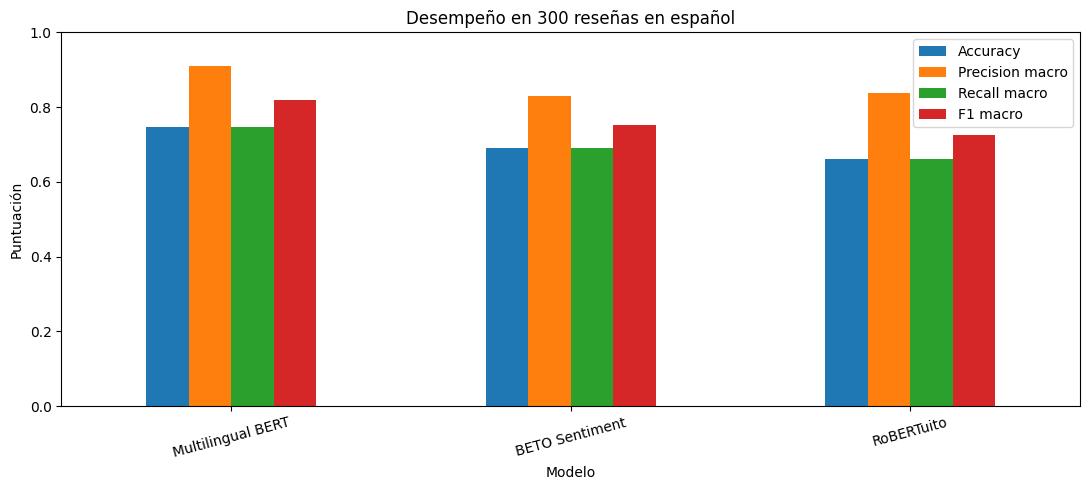

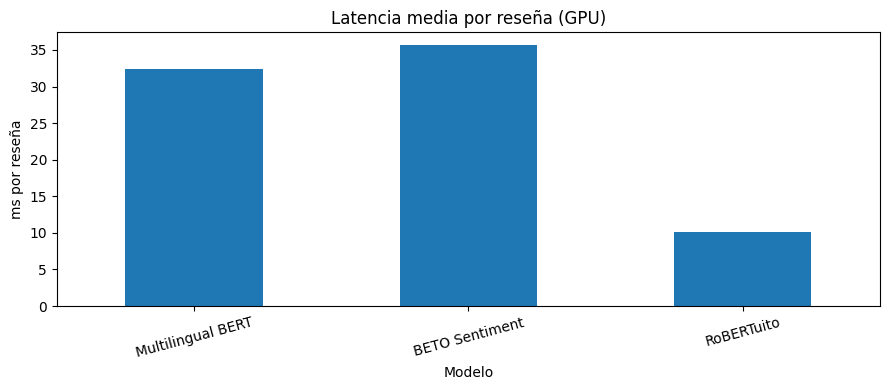

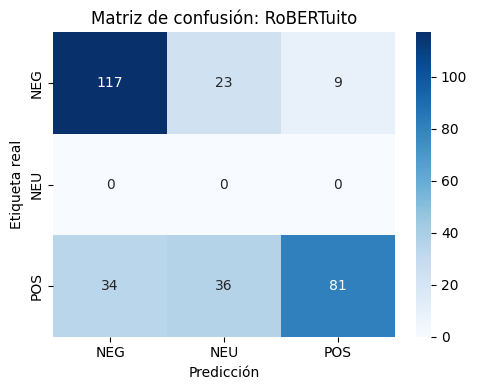

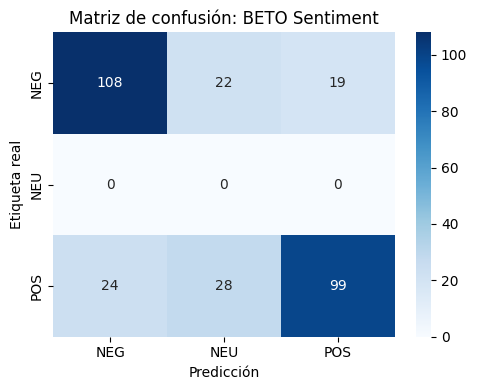

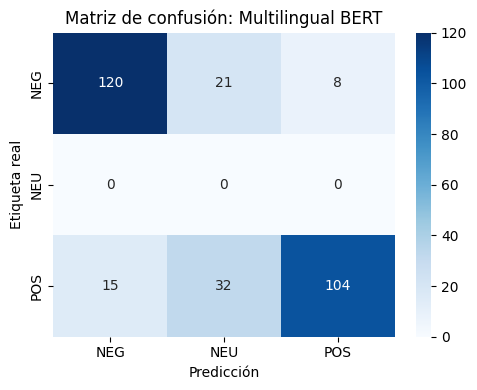

In [ ]:
#################################################  Generación de gráficas de desempeño  #################################################

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


metrics=["Accuracy","Precision macro","Recall macro","F1 macro"]
ax=df_results.set_index("Modelo")[metrics].plot(kind="bar",figsize=(11,5),ylim=(0,1),rot=15,title="Desempeño en 300 reseñas en español")
ax.set_ylabel("Puntuación");plt.tight_layout();plt.show()
ax=df_results.plot(x="Modelo",y="Latencia/muestra (ms)",kind="bar",legend=False,figsize=(9,4),rot=15,title="Latencia media por reseña (GPU)")
ax.set_ylabel("ms por reseña");plt.tight_layout();plt.show()


# Matrices de confusión
for name,cm in matrices.items():
    plt.figure(figsize=(5,4))
    sns.heatmap(cm,annot=True, fmt="d", cmap="Blues", xticklabels=["NEG","NEU","POS"], yticklabels=["NEG","NEU","POS"])
    plt.title("Matriz de confusión: "+name)
    plt.xlabel("Predicción")
    plt.ylabel("Etiqueta real")
    plt.tight_layout()
    plt.show()


In [ ]:
########################################################  Conclusiones parciales  #######################################################

# Impresión de resultados
best_f1 = df_results.loc[df_results["F1 macro"].idxmax()]
fastest = df_results.loc[df_results["Latencia/muestra (ms)"].idxmin()]

print("CONCLUSIONES PARCIALES")
print(f"Mayor F1 macro: {best_f1['Modelo']} ({best_f1['F1 macro']:.3f})")
print(f"Menor latencia: {fastest['Modelo']} ({fastest['Latencia/muestra (ms)']:.2f} ms/reseña)")
print("Diferencia de F1 macro entre mejor y peor:",round(df_results['F1 macro'].max()-df_results['F1 macro'].min(),4))
print("Recomendación preliminar:",best_f1['Modelo'],"por F1 macro; validar el costo, la licencia y el riesgo de uso antes de desplegar.")
print("Limitaciones: traducción automática, 300 reseñas, etiquetas reales binarias, salida neutral en algunos modelos y distintos dominios de entrenamiento.")

# Exporta resultados
df_results.to_csv("comparativa_modelos_act4.csv",index=False)
pd.DataFrame({"text":texts,"real":true_labels,**{name:predictions[name] for name in MODELS}}).to_csv("predicciones_act4.csv",index=False)
print("Exportados: comparativa_modelos_act4.csv y predicciones_act4.csv")




CONCLUSIONES PARCIALES
Mayor F1 macro: Multilingual BERT (0.818)
Menor latencia: RoBERTuito (10.11 ms/reseña)
Diferencia de F1 macro entre mejor y peor: 0.0919
Recomendación preliminar: Multilingual BERT por F1 macro; validar el costo, la licencia y el riesgo de uso antes de desplegar.
Limitaciones: traducción automática, 300 reseñas, etiquetas reales binarias, salida neutral en algunos modelos y distintos dominios de entrenamiento.
Exportados: comparativa_modelos_act4.csv y predicciones_act4.csv
